K-Fold Cross Validation is a technique used to assess the performance of a machine learning model by splitting the dataset into multiple subsets (or "folds").

How It Works:
The dataset is divided into K equal-sized folds.
The model is trained K times, each time using K-1 folds for training and the remaining 1 fold for validation.
The average performance (e.g., accuracy, precision, recall) is calculated over all K iterations.
Advantages:
✔ Reduces bias and variance compared to a single train-test split.
✔ Uses the entire dataset for both training and validation.

In [ ]:
from sklearn.model_selection import KFold
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

In [ ]:
# Generate a synthetic dataset
X, y = make_classification(n_samples=1000, n_features=10, random_state=42)

In [ ]:
y[0:10]

array([0, 1, 1, 0, 1, 0, 0, 1, 1, 0])

In [ ]:
X

array([[ 0.96479937, -0.06644898,  0.98676805, ..., -1.2101605 ,
        -0.62807677,  1.22727382],
       [-0.91651053, -0.56639459, -1.00861409, ..., -0.98453405,
         0.36389642,  0.20947008],
       [-0.10948373, -0.43277388, -0.4576493 , ..., -0.2463834 ,
        -1.05814521, -0.29737608],
       ...,
       [ 1.67463306,  1.75493307,  1.58615382, ...,  0.69272276,
        -1.50384972,  0.22526412],
       [-0.77860873, -0.83568901, -0.19484228, ..., -0.49735437,
         2.47213818,  0.86718741],
       [ 0.24845351, -1.0034389 ,  0.36046013, ...,  0.77323999,
         0.1857344 ,  1.41641179]])

In [ ]:
X.shape

(1000, 10)

In [ ]:
# Define K-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
kf

KFold(n_splits=5, random_state=42, shuffle=True)

In [ ]:
y

array([0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,

In [ ]:
# Perform K-Fold CV
accuracies = []

for i, j in kf.split(X,y):
    X_train, X_test = X[i], X[j]
    y_train, y_test = y[i], y[j]

    # Create and train the model for each fold
    #Create a Decision Tree Classifier
    model=DecisionTreeClassifier()

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

This line starts a loop that iterates through each split generated by the kf (KFold) object. In each iteration, i gets the indices for the training data, and j gets the indices for the testing (or validation) data.

In [ ]:
accuracies

[0.845, 0.915, 0.85, 0.88, 0.88]

In [ ]:
print(f'K-Fold Accuracy Scores: {accuracies}')
print(f'Average Accuracy: {np.mean(accuracies):.4f}')

K-Fold Accuracy Scores: [0.845, 0.915, 0.85, 0.88, 0.88]
Average Accuracy: 0.8740


In [ ]:
accuracies

[0.84, 0.895, 0.845, 0.88, 0.9]

In [ ]:
len(X_test)

200

In [ ]:
len(X_train)

800

**StratifiedKFold**
*italicised text*

Stratified K-Fold is a variation of K-Fold that ensures each fold has a similar distribution of class labels (useful for imbalanced datasets).

How It Works:
The dataset is divided into K folds while maintaining the proportion of class labels in each fold.
The model is trained and validated in the same way as K-Fold.
Advantages:
✔ Ensures balanced class distribution across folds, reducing bias.

In [ ]:
from sklearn.model_selection import StratifiedKFold



In [ ]:
# Define Stratified K-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
accuracies = [] # Reset accuracies for Stratified K-Fold

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Create and train the model for each fold
    model = RandomForestClassifier(n_estimators=100, random_state=42) # Re-instantiate model for each fold or use a fresh one
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

In [ ]:
accuracies

[0.84, 0.91, 0.86, 0.88, 0.895]

In [ ]:
print(f'Stratified K-Fold Accuracy Scores: {accuracies}')
print(f'Average Accuracy: {np.mean(accuracies):.4f}')

Stratified K-Fold Accuracy Scores: [0.84, 0.91, 0.86, 0.88, 0.895]
Average Accuracy: 0.8770


In [ ]:
print(f'Average Accuracy from current `accuracies` variable: {np.mean(accuracies):.4f}')

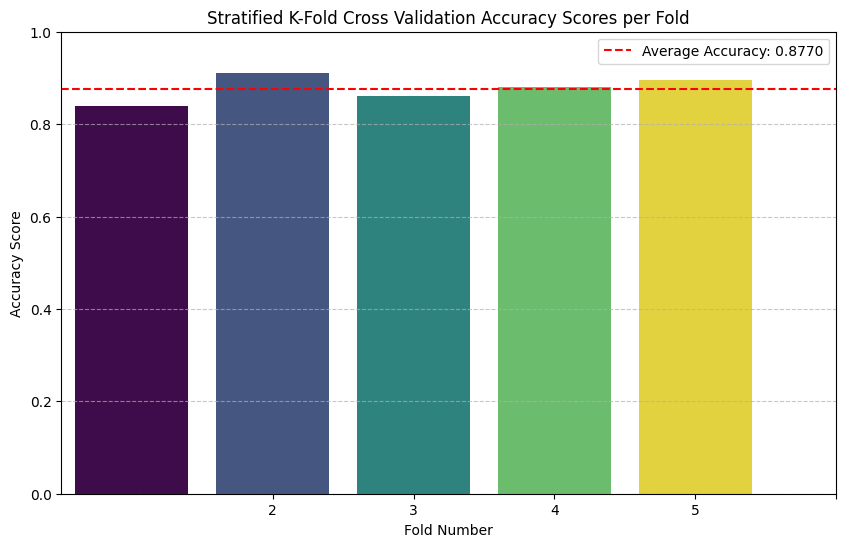

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a list of fold numbers for x-axis
folds = range(1, len(accuracies) + 1)

plt.figure(figsize=(10, 6))
sns.barplot(x=list(folds), y=accuracies, hue=list(folds), palette='viridis', legend=False)
plt.axhline(np.mean(accuracies), color='red', linestyle='--', label=f'Average Accuracy: {np.mean(accuracies):.4f}')

plt.title('Stratified K-Fold Cross Validation Accuracy Scores per Fold')
plt.xlabel('Fold Number')
plt.ylabel('Accuracy Score')
plt.ylim(0, 1) # Accuracy scores are between 0 and 1
plt.xticks(folds)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()